# Tugas 1 - Klasifikasi Jenis Suara dengan kNN

Dataset `voice.csv` berisi 3.168 data suara dengan 20 fitur akustik dan 1 label (`male`/`female`). Tujuan tugas ini adalah membangun model kNN untuk mengklasifikasikan jenis suara, memilih fitur yang paling optimal, serta menentukan nilai K terbaik.

## 1. Load Data

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cari dataset: folder lokal -> /content (Colab) -> Google Drive -> GitHub
GITHUB_URL = 'https://raw.githubusercontent.com/oninonins/Machine-learning-/main/JS09/voice.csv'
DATA_CANDIDATES = [
    'voice.csv',
    '/content/voice.csv',
    '/content/drive/MyDrive/voice.csv',
    GITHUB_URL,
]

DATA_PATH = next(
    (p for p in DATA_CANDIDATES
     if not p.startswith('http') and os.path.exists(p)),
    None,
)

if DATA_PATH is None:
    DATA_PATH = GITHUB_URL

try:
    data = pd.read_csv(DATA_PATH)
except Exception as exc:
    raise FileNotFoundError(
        'voice.csv tidak ditemukan. Letakkan file di folder notebook, '
        'upload ke /content, atau sesuaikan DATA_CANDIDATES.'
    ) from exc

print('Dataset:', DATA_PATH)
data.head()

Dataset: https://raw.githubusercontent.com/oninonins/Machine-learning-/main/JS09/voice.csv


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


## 2. Eksplorasi Data

In [4]:
# ukuran dan struktur data
print('Ukuran data:', data.shape)
data.info()

Ukuran data: (3168, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   meanfreq  3168 non-null   float64
 1   sd        3168 non-null   float64
 2   median    3168 non-null   float64
 3   Q25       3168 non-null   float64
 4   Q75       3168 non-null   float64
 5   IQR       3168 non-null   float64
 6   skew      3168 non-null   float64
 7   kurt      3168 non-null   float64
 8   sp.ent    3168 non-null   float64
 9   sfm       3168 non-null   float64
 10  mode      3168 non-null   float64
 11  centroid  3168 non-null   float64
 12  meanfun   3168 non-null   float64
 13  minfun    3168 non-null   float64
 14  maxfun    3168 non-null   float64
 15  meandom   3168 non-null   float64
 16  mindom    3168 non-null   float64
 17  maxdom    3168 non-null   float64
 18  dfrange   3168 non-null   float64
 19  modindx   3168 non-null   float64
 20  label 

In [5]:
# statistik deskriptif
data.describe()

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,mode,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx
count,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000
mean,0.180907,0.057126,0.185621,0.140456,0.224765,0.084309,3.140168,36.568461,0.895127,0.408216,0.165282,0.180907,0.142807,0.036802,0.258842,0.829211,0.052647,5.047277,4.994630,0.173752
std,0.029918,0.016652,0.036360,0.048680,0.023639,0.042783,4.240529,134.928661,0.044980,0.177521,0.077203,0.029918,0.032304,0.019220,0.030077,0.525205,0.063299,3.521157,3.520039,0.119454
min,0.039363,0.018363,0.010975,0.000229,0.042946,0.014558,0.141735,2.068455,0.738651,0.036876,0.000000,0.039363,0.055565,0.009775,0.103093,0.007812,0.004883,0.007812,0.000000,0.000000
25%,0.163662,0.041954,0.169593,0.111087,0.208747,0.042560,1.649569,5.669547,0.861811,0.258041,0.118016,0.163662,0.116998,0.018223,0.253968,0.419828,0.007812,2.070312,2.044922,0.099766
50%,0.184838,0.059155,0.190032,0.140286,0.225684,0.094280,2.197101,8.318463,0.901767,0.396335,0.186599,0.184838,0.140519,0.046110,0.271186,0.765795,0.023438,4.992188,4.945312,0.139357
75%,0.199146,0.067020,0.210618,0.175939,0.243660,0.114175,2.931694,13.648905,0.928713,0.533676,0.221104,0.199146,0.169581,0.047904,0.277457,1.177166,0.070312,7.007812,6.992188,0.209183
max,0.251124,0.115273,0.261224,0.247347,0.273469,0.252225,34.725453,1309.612887,0.981997,0.842936,0.280000,0.251124,0.237636,0.204082,0.279114,2.957682,0.458984,21.867188,21.843750,0.932374


In [6]:
# cek missing value, duplikat, dan distribusi label
print('Jumlah missing value:', data.isnull().sum().sum())
print('Jumlah data duplikat:', data.duplicated().sum())
print(data['label'].value_counts())

Jumlah missing value: 0
Jumlah data duplikat: 2
label
male      1584
female    1584
Name: count, dtype: int64


## 3. Preprocessing

Dua baris duplikat dihapus agar data yang sama tidak muncul sekaligus pada data latih dan data uji. Label diubah menjadi angka (`male = 0`, `female = 1`).

In [7]:
# hapus data duplikat
data = data.drop_duplicates().reset_index(drop=True)
print('Ukuran data setelah drop duplikat:', data.shape)

# encode label: male = 0, female = 1
data['label'] = data['label'].map({'male': 0, 'female': 1})
data['label'].value_counts()

Ukuran data setelah drop duplikat: (3166, 21)


,count
label,
0,1583
1,1583


## 4. Visualisasi Data

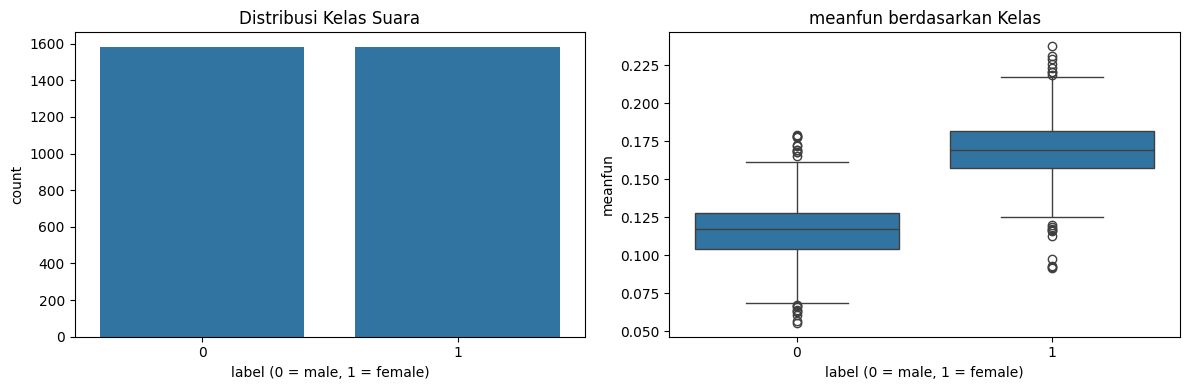

In [8]:
# distribusi label dan contoh fitur dengan korelasi tertinggi
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=data, x='label', ax=axes[0])
axes[0].set_title('Distribusi Kelas Suara')
axes[0].set_xlabel('label (0 = male, 1 = female)')

sns.boxplot(data=data, x='label', y='meanfun', ax=axes[1])
axes[1].set_title('meanfun berdasarkan Kelas')
axes[1].set_xlabel('label (0 = male, 1 = female)')

plt.tight_layout()
plt.show()

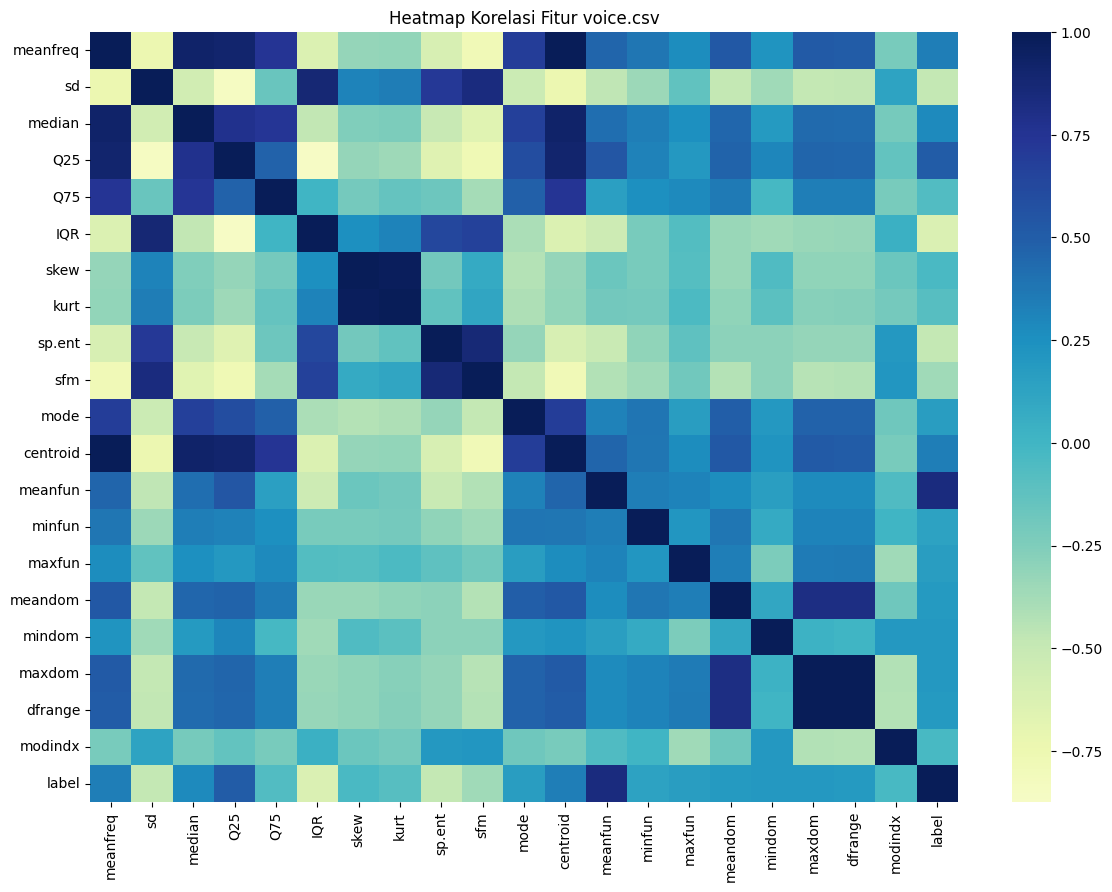

In [9]:
# heatmap korelasi seluruh fitur
plt.figure(figsize=(14, 10))
sns.heatmap(data.corr(), cmap='YlGnBu', center=0)
plt.title('Heatmap Korelasi Fitur voice.csv')
plt.show()

## 5. Pemisahan Data dan Standardisasi

Data dibagi 70% latih dan 30% uji dengan stratifikasi agar proporsi kelas tetap seimbang. Standardisasi dilakukan karena kNN berbasis jarak.

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = data.drop('label', axis=1)
y = data['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

print('Ukuran X_train:', X_train.shape)
print('Ukuran X_test :', X_test.shape)

Ukuran X_train: (2216, 20)
Ukuran X_test : (950, 20)


## 6. Model Baseline kNN

Sebagai pembanding, model kNN dilatih menggunakan seluruh 20 fitur dengan `k = 5`.

In [11]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

knn_base = KNeighborsClassifier(n_neighbors=5)
knn_base.fit(X_train_sc, y_train)

y_pred_base = knn_base.predict(X_test_sc)
print('Akurasi baseline (semua fitur, k=5):', accuracy_score(y_test, y_pred_base))

Akurasi baseline (semua fitur, k=5): 0.9778947368421053


## 7. Analisis Fitur dengan Mutual Information

Mutual Information digunakan untuk mengukur seberapa besar informasi setiap fitur terhadap label. Semakin tinggi skornya, semakin informatif fitur tersebut.

In [12]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif

def mi_score(X, y):
    return mutual_info_classif(X, y, random_state=42)

selector = SelectKBest(score_func=mi_score, k='all')
selector.fit(X_train_sc, y_train)

skor_mi = pd.DataFrame({
    'Fitur': X.columns,
    'MI Score': selector.scores_
}).sort_values('MI Score', ascending=False).reset_index(drop=True)

skor_mi

,Fitur,MI Score
0,meanfun,0.559144
1,IQR,0.452763
2,Q25,0.406224
3,sd,0.303695
4,mode,0.179237
5,sp.ent,0.165358
6,sfm,0.135125
7,meanfreq,0.098611
8,centroid,0.098611
9,mindom,0.097531


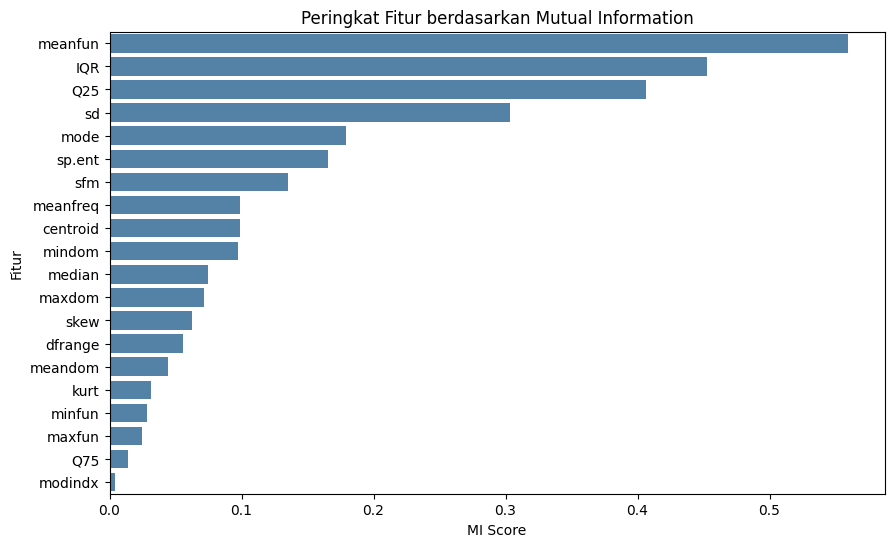

In [13]:
# visualisasi peringkat fitur
plt.figure(figsize=(10, 6))
sns.barplot(data=skor_mi, x='MI Score', y='Fitur', color='steelblue')
plt.title('Peringkat Fitur berdasarkan Mutual Information')
plt.xlabel('MI Score')
plt.ylabel('Fitur')
plt.show()

## 8. Pencarian Jumlah Fitur dan Nilai K Terbaik

Pipeline `StandardScaler -> SelectKBest -> KNeighborsClassifier` diuji dengan `GridSearchCV` 5-fold. Kombinasi yang dicari adalah jumlah fitur 1-20 dan nilai K ganjil 1-29.

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(score_func=mi_score)),
    ('knn', KNeighborsClassifier())
])

param_grid = {
    'selector__k': list(range(1, 21)),
    'knn__n_neighbors': list(range(1, 30, 2))
}

grid = GridSearchCV(pipeline, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid.fit(X_train, y_train)

print('Parameter terbaik:', grid.best_params_)
print('Akurasi CV terbaik:', grid.best_score_)

Parameter terbaik: {'knn__n_neighbors': 3, 'selector__k': 7}
Akurasi CV terbaik: 0.9801415410896224


## 9. Evaluasi Model Terbaik

In [15]:
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

print('Akurasi data uji:', accuracy_score(y_test, y_pred))
print('\nConfusion Matrix:\n', confusion_matrix(y_test, y_pred))
print('\nClassification Report:\n', classification_report(
    y_test, y_pred, target_names=['male', 'female']
))

Akurasi data uji: 0.9821052631578947

Confusion Matrix:
 [[465  10]
 [  7 468]]

Classification Report:
               precision    recall  f1-score   support

        male       0.99      0.98      0.98       475
      female       0.98      0.99      0.98       475

    accuracy                           0.98       950
   macro avg       0.98      0.98      0.98       950
weighted avg       0.98      0.98      0.98       950



In [16]:
# tampilkan fitur yang terpilih
selected_features = list(X.columns[best_model.named_steps['selector'].get_support()])
print('Fitur terpilih:', selected_features)

Fitur terpilih: ['sd', 'Q25', 'IQR', 'sp.ent', 'sfm', 'mode', 'meanfun']


## 10. Grafik Analisis Jumlah Fitur dan Nilai K

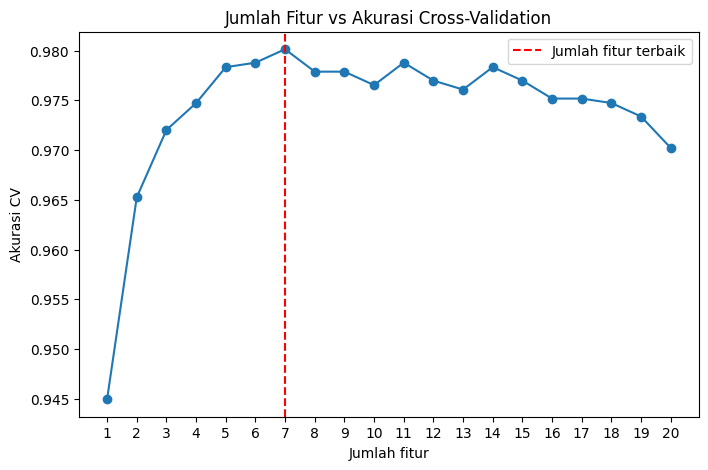

In [17]:
from sklearn.model_selection import cross_val_score

best_k = grid.best_params_['knn__n_neighbors']
n_features = list(range(1, 21))
cv_scores = []

for n in n_features:
    model = Pipeline([
        ('scaler', StandardScaler()),
        ('selector', SelectKBest(score_func=mi_score, k=n)),
        ('knn', KNeighborsClassifier(n_neighbors=best_k))
    ])
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy', n_jobs=-1)
    cv_scores.append(scores.mean())

plt.figure(figsize=(8, 5))
plt.plot(n_features, cv_scores, marker='o')
plt.axvline(x=grid.best_params_['selector__k'], color='r', linestyle='--',
            label='Jumlah fitur terbaik')
plt.title('Jumlah Fitur vs Akurasi Cross-Validation')
plt.xlabel('Jumlah fitur')
plt.ylabel('Akurasi CV')
plt.xticks(n_features)
plt.legend()
plt.show()

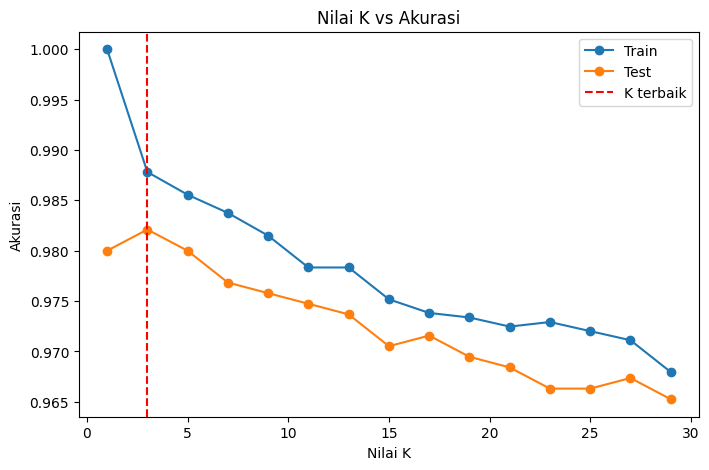

In [18]:
# kurva akurasi train dan test terhadap nilai K
ks = list(range(1, 30, 2))
acc_train = []
acc_test = []

for k in ks:
    model = Pipeline([
        ('scaler', StandardScaler()),
        ('selector', SelectKBest(score_func=mi_score, k=grid.best_params_['selector__k'])),
        ('knn', KNeighborsClassifier(n_neighbors=k))
    ])
    model.fit(X_train, y_train)
    acc_train.append(model.score(X_train, y_train))
    acc_test.append(model.score(X_test, y_test))

plt.figure(figsize=(8, 5))
plt.plot(ks, acc_train, marker='o', label='Train')
plt.plot(ks, acc_test, marker='o', label='Test')
plt.axvline(x=best_k, color='r', linestyle='--', label='K terbaik')
plt.title('Nilai K vs Akurasi')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.legend()
plt.show()

## 11. Analisis Hasil

Seluruh nilai pada bagian ini diambil dari output aktual notebook.

### Fitur yang digunakan

Berdasarkan `SelectKBest` dengan Mutual Information dan `GridSearchCV`, jumlah fitur optimal adalah **7 fitur**, yaitu:

| Peringkat | Fitur | MI Score |
|---|---|---|
| 1 | `meanfun` | 0.5591 |
| 2 | `IQR` | 0.4528 |
| 3 | `Q25` | 0.4062 |
| 4 | `sd` | 0.3037 |
| 5 | `mode` | 0.1792 |
| 6 | `sp.ent` | 0.1654 |
| 7 | `sfm` | 0.1351 |

`meanfun` (rata-rata frekuensi fundamental) merupakan fitur paling informatif karena perbedaan pitch suara male dan female sangat jelas. Fitur distribusi frekuensi seperti `IQR`, `Q25`, dan `sd` juga membantu memisahkan kedua kelas.

### Nilai K terbaik

Nilai **K = 3** menghasilkan akurasi terbaik dengan **akurasi cross-validation 0.9801** dan **akurasi data uji 0.9821**.

- **K = 1** memberikan akurasi latih sempurna (1.0000), tetapi akurasi uji lebih rendah. Kondisi ini menunjukkan overfitting karena model hanya mengikuti satu tetangga terdekat yang sangat sensitif terhadap noise.
- **K = 3** memberikan keseimbangan terbaik antara akurasi latih (0.9878) dan akurasi uji (0.9821).
- Nilai K yang semakin besar cenderung menurunkan akurasi uji karena batas keputusan menjadi terlalu halus (underfitting).

### Perbandingan dengan baseline

Model baseline dengan seluruh 20 fitur dan `k = 5` memperoleh akurasi **0.9779**. Setelah fitur diseleksi menjadi 7 fitur dan `k = 3`, akurasi meningkat menjadi **0.9821**. Penambahan fitur setelah 7 fitur justru menurunkan akurasi cross-validation (misalnya 20 fitur menjadi 0.9702), sehingga fitur yang kurang informatif cenderung menambah noise dan dimensi data.

### Evaluasi klasifikasi

Confusion matrix model terbaik:

```
[[465  10]
 [  7 468]]
```

Model mampu mengklasifikasikan kelas **male** dan **female** dengan precision, recall, dan F1-score sekitar **0.98** untuk kedua kelas. Dengan demikian, kombinasi **7 fitur terbaik dan K = 3** sudah sangat baik untuk kasus klasifikasi jenis suara ini.